# Advance Bank Term Deposit

## Introduction
This notebook provides a detailed analysis of customer behavior and insights into factors influencing term deposit subscription.

## Load Dataset

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv("data.csv")

df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## Customer Demographics Analysis

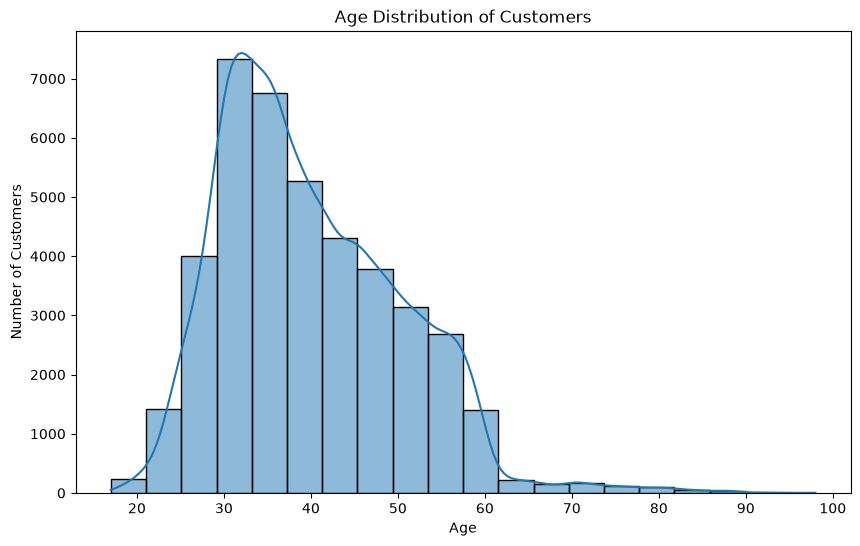

Minimum Age: 17
Maximum Age: 98
Average Age: 40.02
Median Age: 38.0


In [4]:
# Age distribution

# Age Distribution of Customers

plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='age', bins=20, kde=True)

plt.title('Age Distribution of Customers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()


# Age statistics
print("Minimum Age:", df['age'].min())
print("Maximum Age:", df['age'].max())
print("Average Age:", round(df['age'].mean(), 2))
print("Median Age:", df['age'].median())

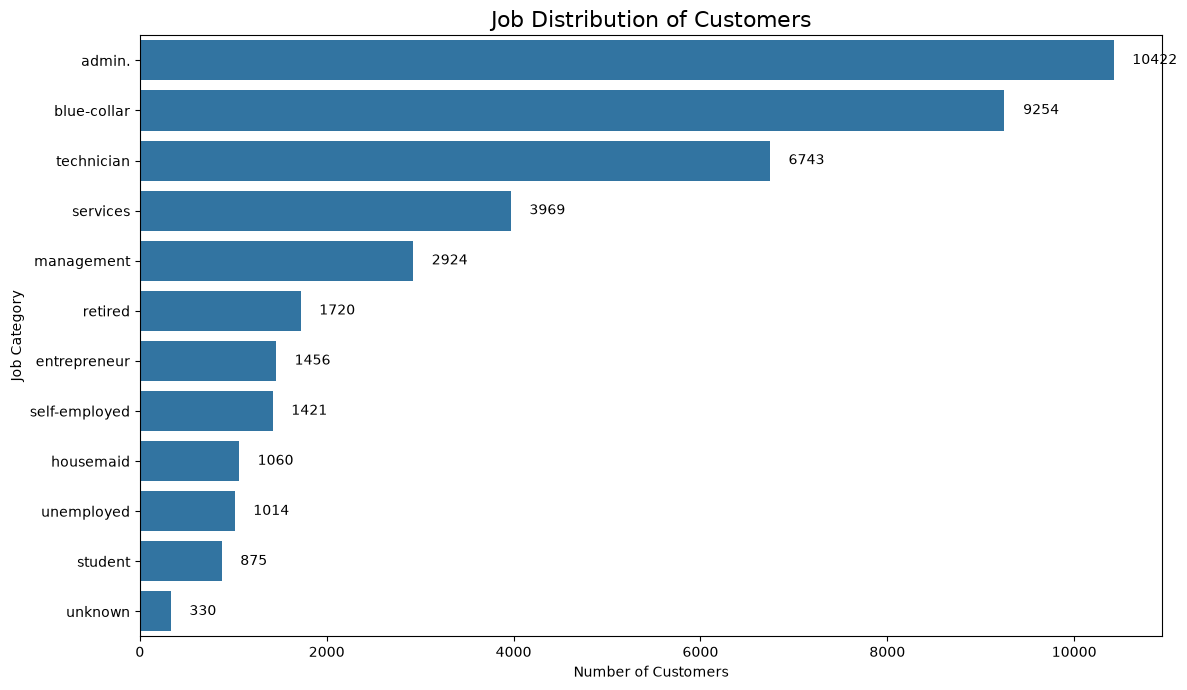

In [5]:
# Job Distribution with customer counts

job_counts = df['job'].value_counts()

plt.figure(figsize=(12, 7))
ax = sns.barplot(x=job_counts.values, y=job_counts.index)

plt.title('Job Distribution of Customers', fontsize=16)
plt.xlabel('Number of Customers')
plt.ylabel('Job Category')

for i, value in enumerate(job_counts.values):
    ax.text(value + 200, i, str(value), va='center')

plt.tight_layout()
plt.show()

## Balance & Deposit Trends

y
no     220.844807
yes    553.191164
Name: duration, dtype: float64


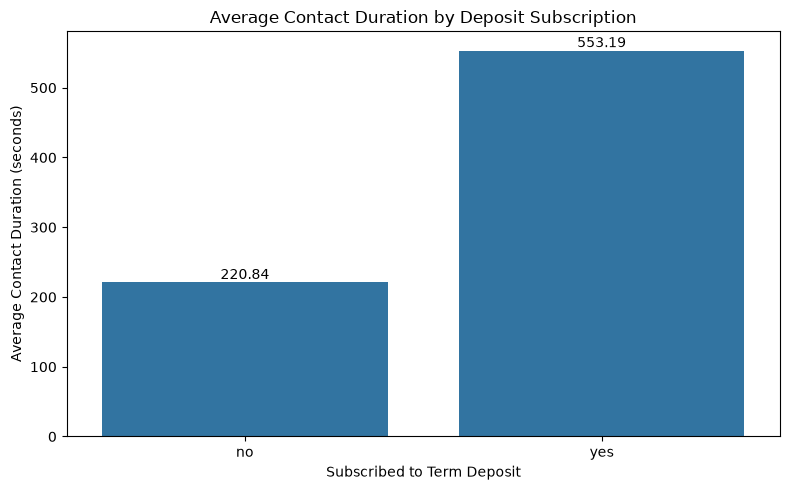

In [6]:
# Average contact duration by deposit subscription

avg_duration = df.groupby('y')['duration'].mean()
print(avg_duration)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=avg_duration.index,
    y=avg_duration.values
)

plt.title('Average Contact Duration by Deposit Subscription')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Average Contact Duration (seconds)')

for i, value in enumerate(avg_duration.values):
    ax.text(i, value + 5, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

## Campaign Effectiveness

y             no    yes
contact                
cellular   85.26  14.74
telephone  94.77   5.23


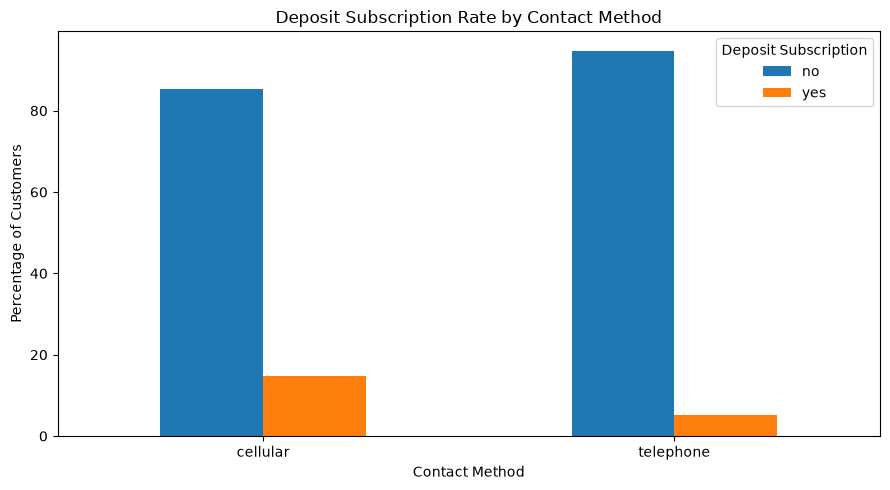

In [8]:
# Contact method analysis# Contact Method Analysis

# Contact Method Analysis

contact_subscription = pd.crosstab(
    df['contact'],
    df['y'],
    normalize='index'
) * 100

print(contact_subscription.round(2))

# Visualization
contact_subscription.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Deposit Subscription Rate by Contact Method')
plt.xlabel('Contact Method')
plt.ylabel('Percentage of Customers')
plt.legend(title='Deposit Subscription')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


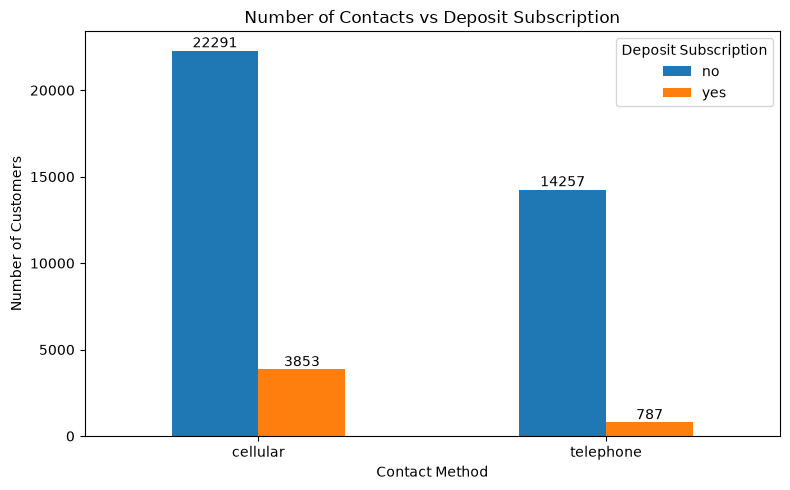

In [10]:
# Number of contacts vs deposit subscription
# Number of Contacts vs Deposit Subscription

contact_deposit = pd.crosstab(df['contact'], df['y'])

ax = contact_deposit.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Number of Contacts vs Deposit Subscription')
plt.xlabel('Contact Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.legend(title='Deposit Subscription')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

## Correlation Heatmap

                     age  duration  campaign     pdays  previous  \
age             1.000000 -0.000866  0.004594 -0.034369  0.024365   
duration       -0.000866  1.000000 -0.071699 -0.047577  0.020640   
campaign        0.004594 -0.071699  1.000000  0.052584 -0.079141   
pdays          -0.034369 -0.047577  0.052584  1.000000 -0.587514   
previous        0.024365  0.020640 -0.079141 -0.587514  1.000000   
emp.var.rate   -0.000371 -0.027968  0.150754  0.271004 -0.420489   
cons.price.idx  0.000857  0.005312  0.127836  0.078889 -0.203130   
cons.conf.idx   0.129372 -0.008173 -0.013733 -0.091342 -0.050936   
euribor3m       0.010767 -0.032897  0.135133  0.296899 -0.454494   
nr.employed    -0.017725 -0.044703  0.144095  0.372605 -0.501333   

                emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  \
age                -0.000371        0.000857       0.129372   0.010767   
duration           -0.027968        0.005312      -0.008173  -0.032897   
campaign            0.150754 

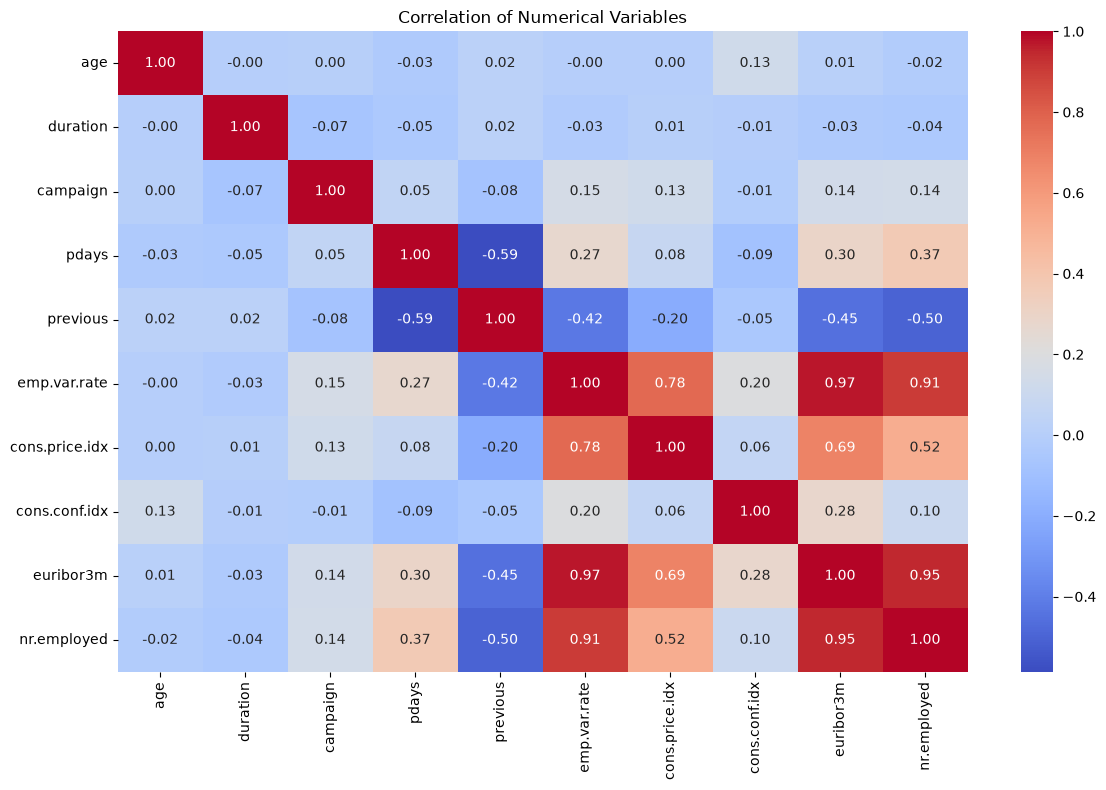

In [11]:
# Correlation of numerical variables

correlation = df.corr(numeric_only=True)

print(correlation)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation of Numerical Variables')
plt.tight_layout()
plt.show()

## Predictive Modeling (Logistic Regression)

In [15]:
# Encode Categorical Variables
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)
print("Encoded Data:")
print(df_encoded.head())
print("\nShape of encoded data:", df_encoded.shape)
# Predictions using Logistic Regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
X = df_encoded.drop('y_yes', axis=1)
y = df_encoded['y_yes']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
# Model Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(accuracy * 100, 2), "%")
# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
# Actual vs Predicted Values
prediction_result = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})
print("\nActual vs Predicted:")
print(prediction_result.head(20))

Encoded Data:
   age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  \
0   56       261         1    999         0           1.1          93.994   
1   57       149         1    999         0           1.1          93.994   
2   37       226         1    999         0           1.1          93.994   
3   40       151         1    999         0           1.1          93.994   
4   56       307         1    999         0           1.1          93.994   

   cons.conf.idx  euribor3m  nr.employed  ...  month_nov  month_oct  \
0          -36.4      4.857       5191.0  ...          0          0   
1          -36.4      4.857       5191.0  ...          0          0   
2          -36.4      4.857       5191.0  ...          0          0   
3          -36.4      4.857       5191.0  ...          0          0   
4          -36.4      4.857       5191.0  ...          0          0   

   month_sep  day_of_week_mon  day_of_week_thu  day_of_week_tue  \
0          0                1

C:\Users\priya\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 5000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=5000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


                          Feature  Importance
42                      month_mar    0.680960
6                  cons.price.idx    0.389168
51           poutcome_nonexistent    0.282496
38                      month_aug    0.257920
41                      month_jun    0.257047
40                      month_jul    0.256593
14                    job_retired    0.184062
50                day_of_week_wed    0.159570
49                day_of_week_tue    0.147514
17                    job_student    0.132505
52               poutcome_success    0.092683
45                      month_oct    0.075158
18                 job_technician    0.066514
29    education_university.degree    0.062549
21                marital_married    0.056235
19                 job_unemployed    0.038085
48                day_of_week_thu    0.025945
30              education_unknown    0.017459
24             education_basic.6y    0.017261
7                   cons.conf.idx    0.016969
27           education_illiterate 

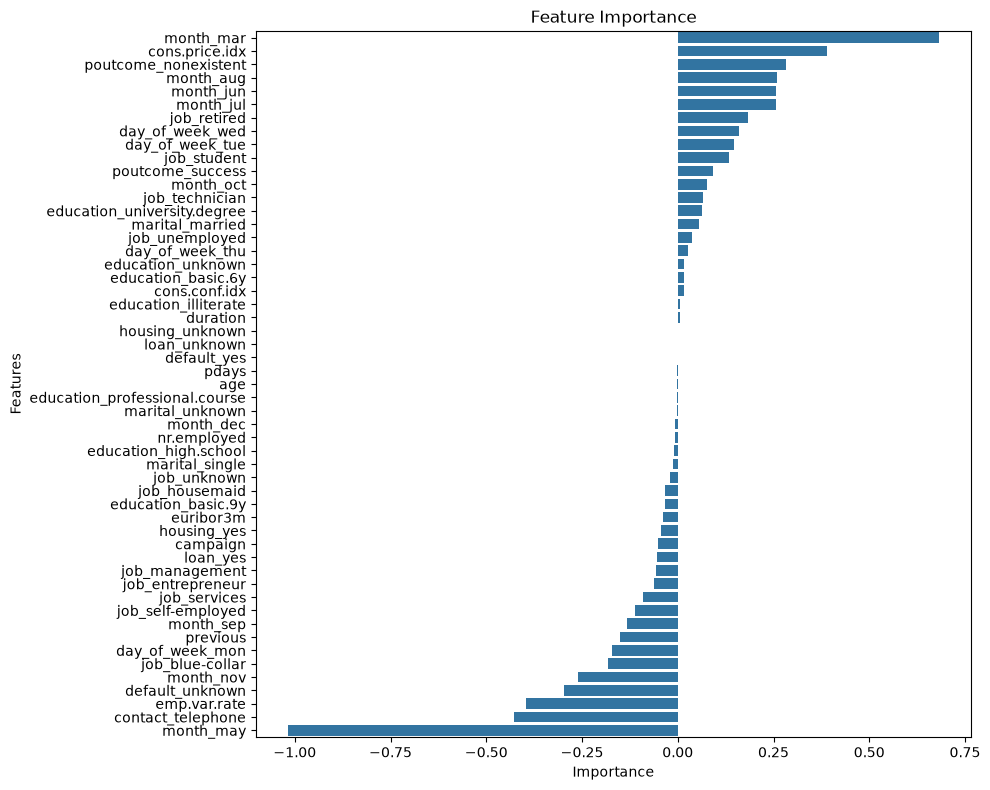

In [14]:
# Feature importance

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.coef_[0]
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

# Plot Feature Importance

plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')

plt.tight_layout()
plt.show()



## Key Takeaways
- Certain age groups and job categories are more likely to subscribe.
- Higher balances correlate with higher subscription rates.
- Cellular contact is more effective than telephone.
- Campaign duration and number of contacts influence outcomes.
- Logistic regression shows which features are strongest predictors.